# Folgen und Reihen

Wie entsteht ein regelmäßiges Muster aus Zahlen? Was haben Zinsen, die Fibonacci-Spirale und die Summe aller natürlichen Zahlen gemeinsam? In diesem Notebook geht es um **Folgen** - geordnete Listen von Zahlen nach einem festen Bildungsgesetz - und **Reihen** - die Summen dieser Zahlen. Beide Konzepte verbinden Algebra mit Analysis und bilden die Grundlage für Konvergenz, Grenzwerte und unendliche Summen.

### Lernziele

In diesem Abschnitt lernst Du:
- **Was eine Folge ist** und wie man sie formal beschreibt (explizit und rekursiv)
- **Was eine Reihe ist** und wie Partialsummen funktionieren
- **Arithmetische** Folgen und Reihen - konstante Differenz, Gaußsche Summenformel
- **Geometrische** Folgen und Reihen - konstanter Quotient, endliche und unendliche Summe
- **Bildungsgesetze erkennen** - eine Folge analysieren und ihr Gesetz formulieren
- **Konvergenz und Divergenz** - wann nähert sich eine Folge einem Grenzwert?

---

### 1. Was ist eine Folge?

Eine **Zahlenfolge** (kurz **Folge**) ist eine Funktion, die jeder natürlichen Zahl $n \geq 1$ genau eine reelle Zahl zuordnet. Man schreibt $(a_n)_{n \geq 1}$ oder kurz $(a_n)$ und nennt $a_n$ das **$n$-te Folgenglied**.

**Beispiel:** Die Folge der Quadratzahlen: $(a_n) = 1, 4, 9, 16, 25, \ldots$ mit $a_n = n^2$.

Es gibt zwei grundlegende Wege, eine Folge zu beschreiben:

#### Explizite Darstellung
Man gibt eine Formel an, die $a_n$ direkt aus $n$ berechnet - ohne vorherige Glieder zu kennen.

$$a_n = f(n) \qquad \text{z.\,B. } a_n = 2n - 1 \;\;\Rightarrow\;\; 1, 3, 5, 7, 9, \ldots$$

#### Rekursive Darstellung
Man gibt einen **Startwert** (oder mehrere) und eine **Rechenvorschrift** an, die das nächste Glied aus den vorherigen berechnet.

$$a_1 = 1, \quad a_{n+1} = a_n + 2 \qquad \Rightarrow\quad 1, 3, 5, 7, 9, \ldots$$

Beide Darstellungen beschreiben hier dieselbe Folge - die ungeraden Zahlen. Die explizite Form ist praktischer zum Berechnen eines bestimmten Glieds (z.\,B. $a_{100} = 199$), die rekursive Form zeigt dagegen die innere Struktur: „Jedes Glied entsteht, indem man 2 zum vorherigen addiert."

### 2. Was ist eine Reihe?

Addiert man die Glieder einer Folge auf, entsteht eine **Reihe**. Die Summe der *ersten $n$ Glieder* heißt **$n$-te Partialsumme**:

$$S_n = \sum_{k=1}^{n} a_k = a_1 + a_2 + \cdots + a_n$$

Die Folge der Partialsummen $(S_1, S_2, S_3, \ldots)$ ist selbst wieder eine Folge. Wenn diese Folge einen Grenzwert besitzt, spricht man von einer **konvergenten Reihe**:

$$\sum_{k=1}^{\infty} a_k = \lim_{n \to \infty} S_n$$

**Beispiel:** Für $a_k = \frac{1}{2^k}$ gilt $S_n = 1 - \frac{1}{2^n}$ und $\lim_{n \to \infty} S_n = 1$.

---

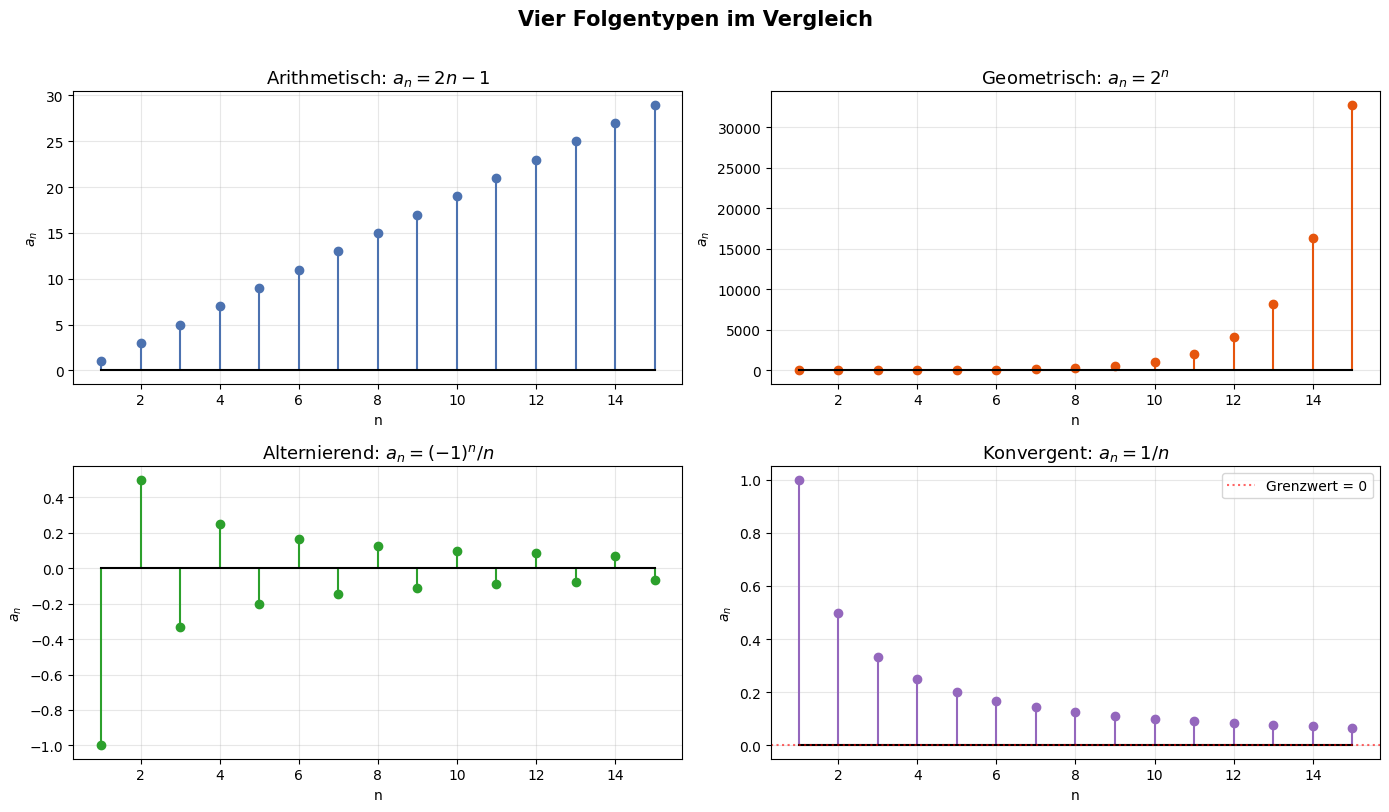

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# KONFIGURATION - Beispielfolgen
# ============================================================

Folgen_Config = [
    {
        "name": "Arithmetisch: $a_n = 2n - 1$",
        "formel": lambda n: 2 * n - 1,
        "farbe": "#4C72B0",
    },
    {
        "name": "Geometrisch: $a_n = 2^n$",
        "formel": lambda n: 2**n,
        "farbe": "#E6550D",
    },
    {
        "name": "Alternierend: $a_n = (-1)^n / n$",
        "formel": lambda n: (-1)**n / n,
        "farbe": "#2CA02C",
    },
    {
        "name": "Konvergent: $a_n = 1/n$",
        "formel": lambda n: 1 / n,
        "farbe": "#9467BD",
    },
]

N_GLIEDER = 15

# ============================================================
# VISUALISIERUNG - Vier Folgentypen
# ============================================================

def visualisiere_folgentypen(configs, n_max):
    """Zeigt vier verschiedene Folgentypen als Punktdiagramme."""
    n = np.arange(1, n_max + 1)
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    axes = axes.flatten()

    for ax, cfg in zip(axes, configs):
        werte = np.array([cfg["formel"](k) for k in n])
        ax.stem(n, werte, linefmt=cfg["farbe"], markerfmt="o", basefmt="k-")
        ax.set_title(cfg["name"], fontsize=13)
        ax.set_xlabel("n")
        ax.set_ylabel("$a_n$")
        ax.grid(True, alpha=0.3)

        # Grenzwert-Linie bei konvergenten Folgen
        if "1/n" in cfg["name"]:
            ax.axhline(0, color="red", linestyle=":", alpha=0.6, label="Grenzwert = 0")
            ax.legend(fontsize=10)

    fig.suptitle("Vier Folgentypen im Vergleich", fontsize=15, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

visualisiere_folgentypen(Folgen_Config, N_GLIEDER)

### 3. Arithmetische Folgen und Reihen

Eine Folge heißt **arithmetisch**, wenn die **Differenz** $d$ zwischen aufeinanderfolgenden Gliedern konstant ist:

$$a_{n+1} - a_n = d \quad \text{für alle } n$$

Die Folge wächst (oder fällt) also gleichmäßig - wie eine Treppe mit immer gleicher Stufenhöhe.

#### Explizite Formel

$$a_n = a_1 + (n-1) \cdot d$$

**Beispiel:** $a_1 = 3$, $d = 5$ ergibt die Folge $3, 8, 13, 18, 23, \ldots$ und das 20. Glied ist $a_{20} = 3 + 19 \cdot 5 = 98$.

#### Gaußsche Summenformel

Die Summe der ersten $n$ Glieder einer arithmetischen Folge lautet:

$$S_n = \frac{n}{2} \cdot (a_1 + a_n) = \frac{n}{2} \cdot \bigl(2a_1 + (n-1)d\bigr)$$

Die Idee dahinter lässt sich an $1 + 2 + 3 + \cdots + 100$ veranschaulichen: Paart man das erste und letzte Glied ($1 + 100 = 101$), das zweite und vorletzte ($2 + 99 = 101$) usw., erhält man 50 Paare mit Summe 101. Also $S_{100} = 50 \cdot 101 = 5050$. Genau das formalisiert die Formel.

**Wichtig:** Arithmetische Reihen *divergieren* immer (außer für $d = 0$ und $a_1 = 0$) - die Partialsummen wachsen unbegrenzt.

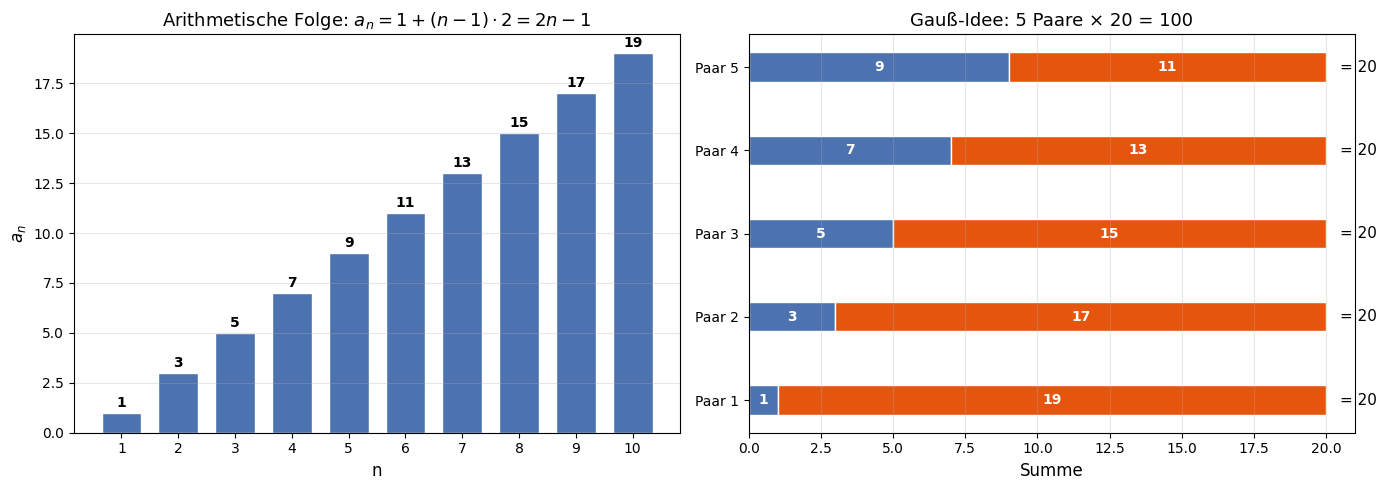

In [4]:
# ============================================================
# KONFIGURATION - Arithmetische Folge
# ============================================================

Arithmetisch_Config = {
    "a1": 1,
    "d": 2,
    "n_max": 10,
    "label_folge": r"$a_n = 1 + (n-1) \cdot 2 = 2n - 1$",
}

# ============================================================
# VISUALISIERUNG - Gauß-Idee: Paare bilden
# ============================================================

def visualisiere_gauss(config):
    """Zeigt die Gaußsche Summenformel als Paarbildung."""
    a1, d, n_max = config["a1"], config["d"], config["n_max"]
    n = np.arange(1, n_max + 1)
    a = a1 + (n - 1) * d
    S = n_max * (a[0] + a[-1]) / 2

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # --- Links: Treppendarstellung ---
    ax = axes[0]
    ax.bar(n, a, color="#4C72B0", edgecolor="white", width=0.7)
    for i, (ni, ai) in enumerate(zip(n, a)):
        ax.text(ni, ai + 0.3, f"{ai:.0f}", ha="center", fontsize=10, fontweight="bold")
    ax.set_xlabel("n", fontsize=12)
    ax.set_ylabel("$a_n$", fontsize=12)
    ax.set_title(f"Arithmetische Folge: {config['label_folge']}", fontsize=13)
    ax.set_xticks(n)
    ax.grid(True, alpha=0.3, axis="y")

    # --- Rechts: Paarbildung (Gauß-Idee) ---
    ax = axes[1]
    paar_summe = a[0] + a[-1]
    n_paare = n_max // 2

    for i in range(n_paare):
        # Zeichne Paare als verbundene Balken
        ax.barh(i, a[i], height=0.35, color="#4C72B0", edgecolor="white", align="center")
        ax.barh(i, a[-(i+1)], height=0.35, left=a[i], color="#E6550D", edgecolor="white", align="center")
        ax.text(a[i] / 2, i, f"{a[i]:.0f}", ha="center", va="center", fontsize=10, color="white", fontweight="bold")
        ax.text(a[i] + a[-(i+1)] / 2, i, f"{a[-(i+1)]:.0f}", ha="center", va="center", fontsize=10, color="white", fontweight="bold")
        ax.text(paar_summe + 0.5, i, f"= {paar_summe:.0f}", ha="left", va="center", fontsize=11)

    ax.set_yticks(range(n_paare))
    ax.set_yticklabels([f"Paar {i+1}" for i in range(n_paare)])
    ax.set_xlabel("Summe", fontsize=12)
    ax.set_title(f"Gauß-Idee: {n_paare} Paare × {paar_summe:.0f} = {S:.0f}", fontsize=13)
    ax.grid(True, alpha=0.3, axis="x")

    plt.tight_layout()
    plt.show()

visualisiere_gauss(Arithmetisch_Config)

### 4. Geometrische Folgen und Reihen

Eine Folge heißt **geometrisch**, wenn der **Quotient** $q$ zwischen aufeinanderfolgenden Gliedern konstant ist:

$$\frac{a_{n+1}}{a_n} = q \quad \text{für alle } n$$

Statt einer gleichmäßigen Treppe (wie bei arithmetischen Folgen) wächst oder schrumpft hier jedes Glied um denselben *Faktor*. Das führt zu exponentiellem Verhalten - schnell steigend für $|q| > 1$, schnell fallend für $|q| < 1$.

#### Explizite Formel

$$a_n = a_1 \cdot q^{n-1}$$

**Beispiel:** $a_1 = 3$, $q = 2$ ergibt $3, 6, 12, 24, 48, \ldots$ und $a_{10} = 3 \cdot 2^9 = 1536$.

#### Endliche geometrische Reihe

Die Summe der ersten $n$ Glieder:

$$S_n = a_1 \cdot \frac{q^n - 1}{q - 1} \qquad (q \neq 1)$$

Für $q = 1$ ist die Summe einfach $S_n = n \cdot a_1$.

#### Unendliche geometrische Reihe

Nur wenn $|q| < 1$ konvergiert die Reihe. Die Partialsummen nähern sich dann einem festen Wert:

$$\sum_{k=0}^{\infty} a_1 \cdot q^k = \frac{a_1}{1 - q} \qquad (|q| < 1)$$

Das liegt daran, dass die Glieder für $|q| < 1$ immer kleiner werden und „fast nichts" mehr zur Summe beitragen. Für $|q| \geq 1$ dagegen wachsen die Glieder (oder bleiben gleich groß), und die Summe explodiert.

**Anwendung:** Zinseszins. Legt man ein Kapital $K_0$ zu einem Zinssatz $p$ (als Dezimalzahl) an, wächst es geometrisch mit $q = 1 + p$:

$$K_n = K_0 \cdot (1 + p)^n$$

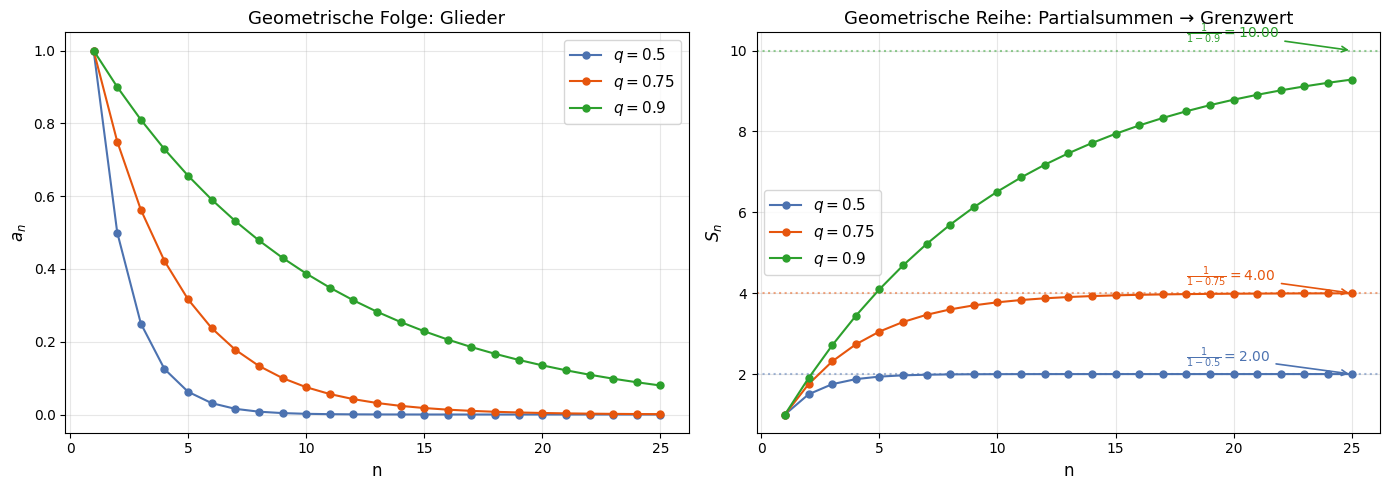

In [5]:
# ============================================================
# KONFIGURATION - Geometrische Reihe
# ============================================================

Geometrisch_Config = {
    "a1": 1,
    "quotienten": [0.5, 0.75, 0.9],
    "n_max": 25,
    "farben": ["#4C72B0", "#E6550D", "#2CA02C"],
}

# ============================================================
# VISUALISIERUNG - Konvergenz der Partialsummen
# ============================================================

def visualisiere_geometrisch(config):
    """Zeigt, wie geometrische Reihen für verschiedene q konvergieren."""
    a1 = config["a1"]
    n = np.arange(1, config["n_max"] + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # --- Links: Folgenglieder ---
    ax = axes[0]
    for q, farbe in zip(config["quotienten"], config["farben"]):
        glieder = a1 * q**(n - 1)
        ax.plot(n, glieder, "o-", color=farbe, markersize=5, label=f"$q = {q}$")

    ax.set_xlabel("n", fontsize=12)
    ax.set_ylabel("$a_n$", fontsize=12)
    ax.set_title("Geometrische Folge: Glieder", fontsize=13)
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)

    # --- Rechts: Partialsummen → Grenzwert ---
    ax = axes[1]
    for q, farbe in zip(config["quotienten"], config["farben"]):
        glieder = a1 * q**(n - 1)
        partial = np.cumsum(glieder)
        grenzwert = a1 / (1 - q)
        ax.plot(n, partial, "o-", color=farbe, markersize=5, label=f"$q = {q}$")
        ax.axhline(grenzwert, color=farbe, linestyle=":", alpha=0.5)
        ax.annotate(
            f"$\\frac{{{a1}}}{{1 - {q}}} = {grenzwert:.2f}$",
            xy=(config["n_max"], grenzwert),
            xytext=(config["n_max"] - 7, grenzwert + 0.3),
            fontsize=10, color=farbe,
            arrowprops=dict(arrowstyle="->", color=farbe, lw=1.2),
        )

    ax.set_xlabel("n", fontsize=12)
    ax.set_ylabel("$S_n$", fontsize=12)
    ax.set_title("Geometrische Reihe: Partialsummen → Grenzwert", fontsize=13)
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

visualisiere_geometrisch(Geometrisch_Config)

### 5. Bildungsgesetze erkennen

In der Praxis bekommt man oft die ersten Glieder einer Folge und muss das Gesetz dahinter entdecken. Hier ein systematischer Ansatz:

#### Strategie

1. **Differenzen bilden:** Berechne $a_{n+1} - a_n$. Sind sie konstant → **arithmetisch** (Differenz $d$).
2. **Quotienten bilden:** Berechne $a_{n+1} / a_n$. Sind sie konstant → **geometrisch** (Quotient $q$).
3. **Muster suchen:** Quadratzahlen, Potenzen, alternierende Vorzeichen ($(-1)^n$), Brüche mit wachsendem Nenner, …
4. **Rekursion prüfen:** Hängt jedes Glied von den *vorherigen* ab? (z.\,B. Fibonacci)

#### Beispiel: Fibonacci-Folge

Die berühmte Fibonacci-Folge ist weder arithmetisch noch geometrisch, sondern rein **rekursiv** definiert:

$$F_1 = 1, \quad F_2 = 1, \quad F_{n+2} = F_n + F_{n+1}$$

Das ergibt $1, 1, 2, 3, 5, 8, 13, 21, 34, 55, \ldots$ - jedes Glied ist die Summe der beiden vorherigen. Für diese Folge gibt es zwar eine explizite Formel (die Binet-Formel mit dem goldenen Schnitt $\varphi$), aber die rekursive Definition ist weitaus natürlicher und einfacher.

**Tipp:** Oft hilft es, die Folge in eine Tabelle zu schreiben und systematisch Differenzen und Quotienten zu berechnen, bevor man rät.

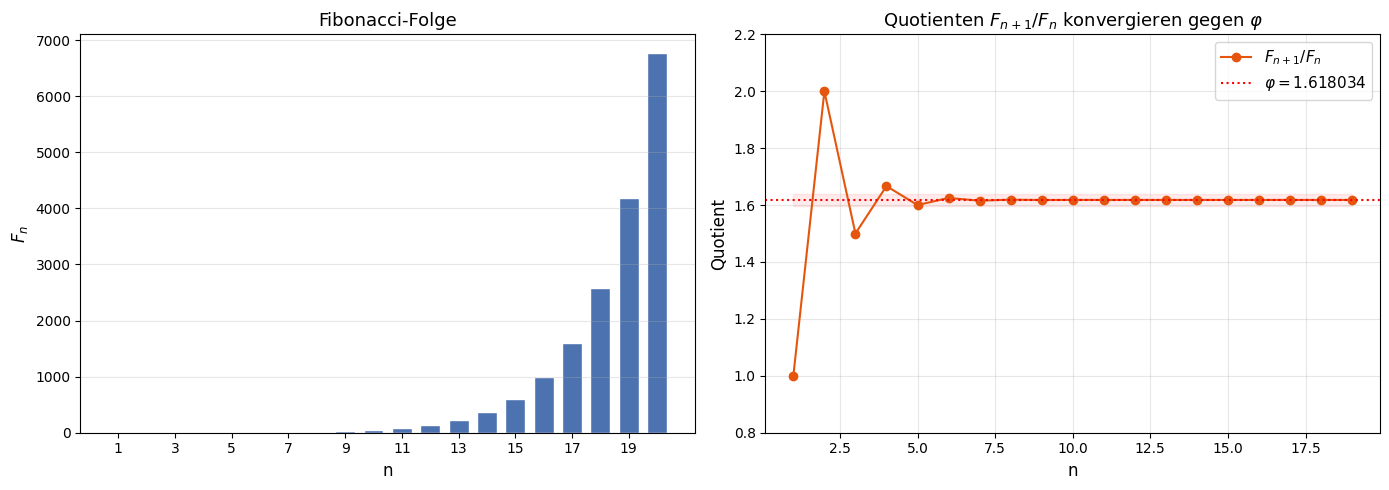

In [6]:
# ============================================================
# KONFIGURATION - Fibonacci und Quotienten-Konvergenz
# ============================================================

Fibonacci_Config = {
    "n_glieder": 20,
    "goldener_schnitt": (1 + np.sqrt(5)) / 2,  # φ ≈ 1.618
}

# ============================================================
# VISUALISIERUNG - Fibonacci-Quotienten → Goldener Schnitt
# ============================================================

def visualisiere_fibonacci(config):
    """Zeigt die Fibonacci-Folge und die Konvergenz der Quotienten gegen φ."""
    n_max = config["n_glieder"]
    phi = config["goldener_schnitt"]

    # Fibonacci berechnen
    fib = [1, 1]
    for _ in range(n_max - 2):
        fib.append(fib[-1] + fib[-2])

    quotienten = [fib[i+1] / fib[i] for i in range(len(fib) - 1)]
    n_q = np.arange(1, len(quotienten) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # --- Links: Fibonacci-Glieder ---
    ax = axes[0]
    n = np.arange(1, n_max + 1)
    ax.bar(n, fib, color="#4C72B0", edgecolor="white", width=0.7)
    ax.set_xlabel("n", fontsize=12)
    ax.set_ylabel("$F_n$", fontsize=12)
    ax.set_title("Fibonacci-Folge", fontsize=13)
    ax.set_xticks(n[::2])
    ax.grid(True, alpha=0.3, axis="y")

    # --- Rechts: Quotienten → φ ---
    ax = axes[1]
    ax.plot(n_q, quotienten, "o-", color="#E6550D", markersize=6, label=r"$F_{n+1} / F_n$")
    ax.axhline(phi, color="red", linestyle=":", linewidth=1.5, label=rf"$\varphi = {phi:.6f}$")
    ax.fill_between(n_q, phi - 0.02, phi + 0.02, color="red", alpha=0.08)
    ax.set_xlabel("n", fontsize=12)
    ax.set_ylabel("Quotient", fontsize=12)
    ax.set_title(r"Quotienten $F_{n+1}/F_n$ konvergieren gegen $\varphi$", fontsize=13)
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0.8, 2.2)

    plt.tight_layout()
    plt.show()

visualisiere_fibonacci(Fibonacci_Config)

### 6. Konvergenz und Divergenz

Wann nähert sich eine Folge einem festen Wert? Die zentrale Frage dieses Abschnitts.

#### Konvergenz

Eine Folge $(a_n)$ **konvergiert** gegen den **Grenzwert** $g$, wenn die Glieder für wachsendes $n$ beliebig nahe an $g$ herankommen:

$$\lim_{n \to \infty} a_n = g$$

Formal: Für jedes noch so kleine $\varepsilon > 0$ gibt es ein $N$, sodass $|a_n - g| < \varepsilon$ für alle $n > N$. Anschaulich bedeutet das: Ab einem bestimmten Index liegen *alle* Glieder im „$\varepsilon$-Schlauch" um $g$.

#### Divergenz

Besitzt eine Folge keinen Grenzwert, heißt sie **divergent**. Es gibt zwei Arten:

- **Bestimmte Divergenz:** $a_n \to +\infty$ oder $a_n \to -\infty$ (die Glieder wachsen unbegrenzt)
- **Unbestimmte Divergenz:** Die Glieder springen hin und her, ohne sich einem Wert zu nähern (z.\,B. $a_n = (-1)^n$)

#### Hinreichende Bedingung: Monoton und beschränkt

Eine Folge, die **monoton wachsend** (oder fallend) und **beschränkt** ist, konvergiert garantiert. Das ist eines der nützlichsten Kriterien - man muss den Grenzwert nicht kennen, um Konvergenz zu beweisen.

#### Wichtige Grenzwerte

| Folge | Grenzwert | Bemerkung |
|-------|-----------|-----------|
| $a_n = \frac{1}{n}$ | $0$ | Harmonische Nullfolge |
| $a_n = \left(1 + \frac{1}{n}\right)^n$ | $e \approx 2{,}718$ | Definition der Eulerschen Zahl |
| $a_n = q^n$ mit $\|q\| < 1$ | $0$ | Geometrische Nullfolge |
| $a_n = \frac{n^k}{c^n}$ ($c > 1$) | $0$ | Exponentielles schlägt polynomiales Wachstum |

> **Verweis:** Eine ausführliche Behandlung von Grenzwerten findest Du im Notebook → **02_Funktionen/02_Grenzwerte**

---

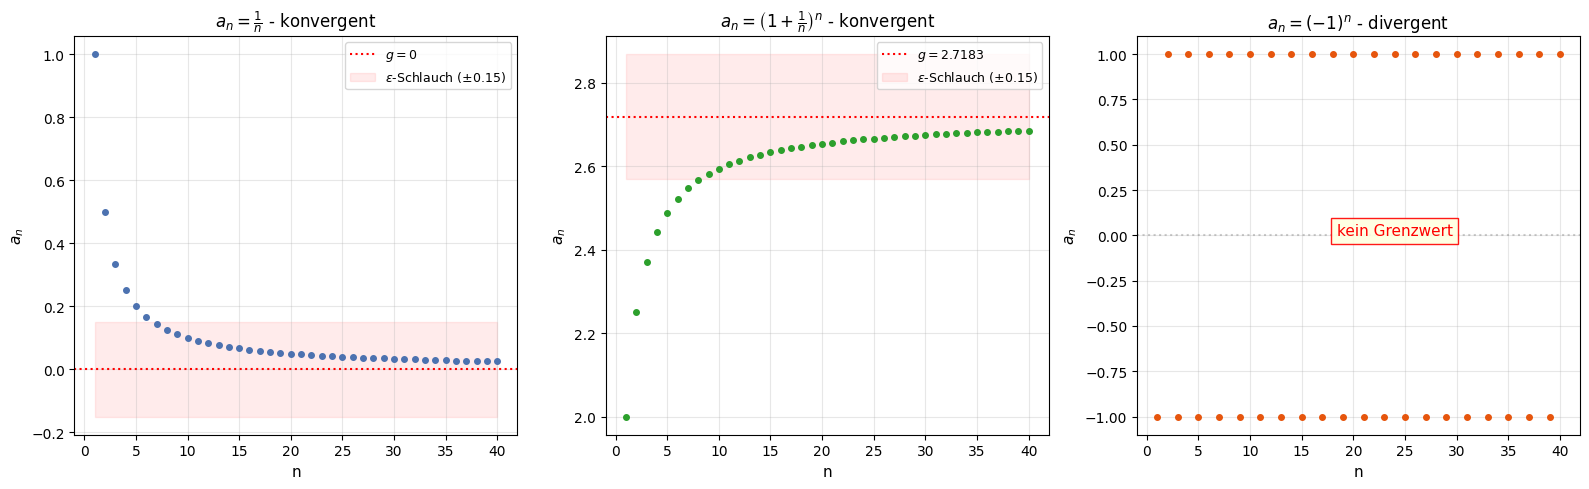

In [7]:
# ============================================================
# KONFIGURATION - Konvergenz vs. Divergenz
# ============================================================

Konvergenz_Config = {
    "epsilon": 0.15,
    "n_max": 40,
    "folgen": [
        {
            "name": r"$a_n = \frac{1}{n}$ - konvergent",
            "formel": lambda n: 1 / n,
            "grenzwert": 0,
            "farbe": "#4C72B0",
        },
        {
            "name": r"$a_n = \left(1 + \frac{1}{n}\right)^n$ - konvergent",
            "formel": lambda n: (1 + 1/n)**n,
            "grenzwert": np.e,
            "farbe": "#2CA02C",
        },
        {
            "name": r"$a_n = (-1)^n$ - divergent",
            "formel": lambda n: (-1)**n,
            "grenzwert": None,
            "farbe": "#E6550D",
        },
    ],
}

# ============================================================
# VISUALISIERUNG - ε-Schlauch und Konvergenzverhalten
# ============================================================

def visualisiere_konvergenz(config):
    """Zeigt konvergente Folgen mit ε-Schlauch und eine divergente Folge."""
    n = np.arange(1, config["n_max"] + 1)
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    for ax, cfg in zip(axes, config["folgen"]):
        werte = np.array([cfg["formel"](k) for k in n])
        ax.plot(n, werte, "o", color=cfg["farbe"], markersize=4)

        if cfg["grenzwert"] is not None:
            g = cfg["grenzwert"]
            eps = config["epsilon"]
            # ε-Schlauch
            ax.axhline(g, color="red", linestyle=":", linewidth=1.5, label=f"$g = {g:.4f}$" if g != 0 else "$g = 0$")
            ax.fill_between(n, g - eps, g + eps, color="red", alpha=0.08, label=rf"$\varepsilon$-Schlauch ($\pm {eps}$)")
            ax.legend(fontsize=9, loc="upper right")
        else:
            ax.axhline(0, color="gray", linestyle=":", alpha=0.4)
            ax.annotate("kein Grenzwert", xy=(config["n_max"] * 0.6, 0),
                        fontsize=11, color="red", ha="center",
                        bbox=dict(facecolor="lightyellow", alpha=0.9, edgecolor="red"))

        ax.set_title(cfg["name"], fontsize=12)
        ax.set_xlabel("n", fontsize=11)
        ax.set_ylabel("$a_n$", fontsize=11)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

visualisiere_konvergenz(Konvergenz_Config)

---

## Verständnis-Check

*Löse die folgenden Aufgaben auf Papier, bevor du die Lösungen aufdeckst.*

**Aufgabe 1:** Gib die ersten 6 Glieder der arithmetischen Folge mit $a_1 = 5$ und $d = -3$ an. Berechne $a_{20}$.

**Aufgabe 2:** Eine geometrische Folge beginnt mit $a_1 = 4$ und $q = \tfrac{1}{2}$. Berechne $S_5$ und den Grenzwert der unendlichen Reihe.

**Aufgabe 3:** Gegeben ist die Folge $2, 6, 18, 54, \ldots$. Ist sie arithmetisch oder geometrisch? Bestimme das Bildungsgesetz und $a_8$.

**Aufgabe 4:** Untersuche die Folge $a_n = \frac{3n + 1}{n + 2}$ auf Konvergenz. Falls sie konvergiert, bestimme den Grenzwert.

**Aufgabe 5:** Berechne mit der Gaußschen Summenformel: $\sum_{k=1}^{50} (4k - 1)$

### Lösungen

<details>
<summary>Lösung Aufgabe 1</summary>

$a_n = 5 + (n-1) \cdot (-3) = 8 - 3n$

Erste 6 Glieder: $5, 2, -1, -4, -7, -10$

$$a_{20} = 8 - 3 \cdot 20 = -52$$
</details>

<details>
<summary>Lösung Aufgabe 2</summary>

$$S_5 = 4 \cdot \frac{1 - (1/2)^5}{1 - 1/2} = 4 \cdot \frac{1 - 1/32}{1/2} = 4 \cdot \frac{31/32}{1/2} = 4 \cdot \frac{31}{16} = \frac{31}{4} = 7{,}75$$

Grenzwert der unendlichen Reihe ($|q| = 0{,}5 < 1$):

$$\sum_{k=0}^{\infty} 4 \cdot \left(\frac{1}{2}\right)^k = \frac{4}{1 - 1/2} = 8$$
</details>

<details>
<summary>Lösung Aufgabe 3</summary>

Differenzen: $6-2=4$, $18-6=12$ → nicht konstant → **nicht arithmetisch**.

Quotienten: $6/2 = 3$, $18/6 = 3$, $54/18 = 3$ → konstant → **geometrisch** mit $q = 3$.

Bildungsgesetz: $a_n = 2 \cdot 3^{n-1}$

$$a_8 = 2 \cdot 3^7 = 2 \cdot 2187 = 4374$$
</details>

<details>
<summary>Lösung Aufgabe 4</summary>

Zähler und Nenner durch $n$ teilen:

$$a_n = \frac{3n + 1}{n + 2} = \frac{3 + 1/n}{1 + 2/n}$$

Für $n \to \infty$ gilt $1/n \to 0$ und $2/n \to 0$:

$$\lim_{n \to \infty} a_n = \frac{3 + 0}{1 + 0} = 3$$

Die Folge **konvergiert** gegen $3$.
</details>

<details>
<summary>Lösung Aufgabe 5</summary>

Die Folge $a_k = 4k - 1$ ist arithmetisch mit $a_1 = 3$, $d = 4$, $n = 50$.

$$a_{50} = 4 \cdot 50 - 1 = 199$$

$$S_{50} = \frac{50}{2} \cdot (3 + 199) = 25 \cdot 202 = 5050$$
</details>

---

## Zusammenfassung

| Konzept | Formel / Kernaussage |
|---------|---------------------|
| **Folge** | Funktion $n \mapsto a_n$, explizit oder rekursiv |
| **Reihe** | Summe der Folgenglieder: $S_n = \sum_{k=1}^{n} a_k$ |
| **Arithmetisch** | $a_n = a_1 + (n-1)d$, Summe: $S_n = \frac{n}{2}(a_1 + a_n)$ |
| **Geometrisch** | $a_n = a_1 \cdot q^{n-1}$, Summe: $S_n = a_1 \cdot \frac{q^n - 1}{q - 1}$ |
| **Geom. Reihe** ($|q|<1$) | $\sum_{k=0}^{\infty} a_1 q^k = \frac{a_1}{1-q}$ |
| **Konvergenz** | $\lim_{n\to\infty} a_n = g$ - Glieder nähern sich $g$ |
| **Divergenz** | Kein Grenzwert (bestimmt ↔ unbestimmt) |
| **Monoton + beschränkt** | ⇒ konvergent |

> **Nächster Schritt:** Folgen und Reihen bilden die Grundlage für die **Analysis** - insbesondere der Zusammenhang zwischen Reihen und Integralen. → Weiter zu **07_Analysis/01_Einführung_in_die_Analysis**

---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Folge | Sequence |
| Reihe | Series |
| Folgenglied | Term (of a sequence) |
| Partialsumme | Partial sum |
| Bildungsgesetz | Formation rule / Closed form |
| Arithmetische Folge | Arithmetic sequence |
| Geometrische Folge | Geometric sequence |
| Differenz (d) | Common difference |
| Quotient (q) | Common ratio |
| Konvergenz | Convergence |
| Divergenz | Divergence |
| Grenzwert | Limit |
| Monoton | Monotonic |
| Beschränkt | Bounded |
| Rekursiv | Recursive |
| Explizit | Explicit |
| Gaußsche Summenformel | Gauss summation formula |
| Fibonacci-Folge | Fibonacci sequence |
| Goldener Schnitt ($\varphi$) | Golden ratio |